В pytorch существует специальный класс, реализующий представленную на прошлом уроке логику хранения картинок

In [1]:
import os
import json
from PIL import Image

import torch
import torch.utils.data as data
import torchvision.transforms.v2 as tfs
import torch.nn as nn
import torch.optim as optim
from tqdm import tqdm
from torchvision.datasets import ImageFolder


class RavelTransform(nn.Module):
    """
    пользовательская трансформация"""
    def forward(self, item):
        return item.ravel()


class DigitNN(nn.Module):
    def __init__(self, input_dim, num_hidden, output_dim):
        super().__init__()
        self.layer1 = nn.Linear(input_dim, num_hidden)
        self.layer2 = nn.Linear(num_hidden, output_dim)

    def forward(self, x):
        x = self.layer1(x)
        x = nn.functional.relu(x)
        x = self.layer2(x)
        return x


model = DigitNN(28 * 28, 32, 10)


transforms = tfs.Compose([tfs.ToImage(),  # преобразование объекта PIL в тензор pytorch
                          tfs.Grayscale(),
                          tfs.ToDtype(torch.float32, scale=True),
                          RavelTransform(),
                          ])

d_train = ImageFolder("dataset/train", transform=transforms)
train_data = data.DataLoader(d_train, batch_size=32, shuffle=True)

optimizer = optim.Adam(params=model.parameters(), lr=0.01)
loss_function = nn.CrossEntropyLoss()
epochs = 2
model.train()

for _e in range(epochs):
    loss_mean = 0
    lm_count = 0

    train_tqdm = tqdm(train_data, leave=True)
    for x_train, y_train in train_tqdm:
        predict = model(x_train)
        loss = loss_function(predict, y_train)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        lm_count += 1
        loss_mean = 1/lm_count * loss.item() + (1 - 1/lm_count) * loss_mean
        train_tqdm.set_description(f"Epoch [{_e+1}/{epochs}], loss_mean={loss_mean:.3f}")

d_test = ImageFolder("dataset/test", transform=transforms)
test_data = data.DataLoader(d_test, batch_size=500, shuffle=False)

Q = 0

# тестирование обученной НС
model.eval()

for x_test, y_test in test_data:
    with torch.no_grad():
        p = model(x_test)
        p = torch.argmax(p, dim=1)
        Q += torch.sum(p == y_test).item()

Q /= len(d_test)
print(Q)

Epoch [2/2], loss_mean=0.185: 100%|██████████| 1875/1875 [00:54<00:00, 34.32it/s]


0.9512


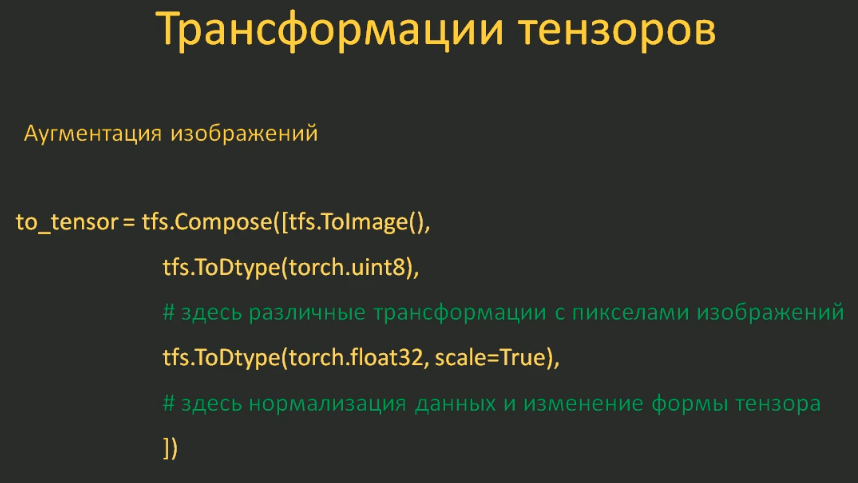

Чтобы работать с объектов как с изображением, его нужно привести к формату uint8. а чтобы подставлять в нейронную сеть. там должен быть float